# 05 — Decision figures: calibration, risk–coverage, escalation, operators

M9 figure notebook for the decision layer (Steps 9–12). It **reads** two frozen
pipeline reports and never refits anything — thresholds, β and tiers come from the
JSON, so a figure can only change if the report changes.

| Report | Case source | What it measures |
| --- | --- | --- |
| `results/decision/m8_decision.json` | **detector alerts** (`rules`, threshold chosen on val at 1 false alarm / household-week) | the deployable trust layer: false alarms, split and partial events all reach the agents |
| `results/decision/m8_decision_events.json` | **injected event windows** (oracle segmentation) | the decision layer given perfect segmentation (upper bound) |

A decision is **correct** when its action is acceptable for the true outcome and, for a
real anomaly, its origin is right (`configs/policy.yaml: acceptable_actions`; a false
alarm is correct only when dismissed with `no_action`).

Regenerate the reports with `make demo` (or `.\tasks.ps1 demo`).

In [1]:
import datetime
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energymind.eda_plots import (
    BLUE, GREEN, GREY, ORANGE, PURPLE, VERM, _fig, _finish, _label, _sub,
)

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
FIGDIR = REPO / "results" / "figures" / "decision"
PATHS = {
    "alerts": REPO / "results" / "decision" / "m8_decision.json",
    "events": REPO / "results" / "decision" / "m8_decision_events.json",
}
reports = {name: json.loads(p.read_text(encoding="utf-8")) for name, p in PATHS.items()}


def validate_report(rep: dict, name: str) -> None:
    """Fail fast if a frozen report lacks what the figures need."""
    need = {"case_source", "thresholds", "coefficients", "coefficients_ci", "risk_coverage",
            "cases", "n_val", "n_test", "ece_test", "operator_simulation", "tier_counts"}
    missing = need - set(rep)
    if missing:
        raise KeyError(f"{name}: report missing {sorted(missing)} - rerun `make demo`")
    assert rep["case_source"] == name, f"{name}: wrong case source {rep['case_source']}"
    assert len(rep["cases"]) == rep["n_val"] + rep["n_test"], f"{name}: case count mismatch"
    assert rep["leakage_violations"] == 0, f"{name}: time leakage in retrieval"
    assert rep["audit"]["valid"], f"{name}: audit chain broken"


sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
                     text=True, cwd=REPO).stdout.strip() or "unknown"
for name, rep in reports.items():
    validate_report(rep, name)
    mtime = datetime.datetime.fromtimestamp(PATHS[name].stat().st_mtime)
    print(f"{name:<6} {PATHS[name].name:<28} git={sha} mtime={mtime:%Y-%m-%d %H:%M} "
          f"val={rep['n_val']} test={rep['n_test']} "
          f"false alarms={rep['false_alarm_cases']['test']} "
          f"tau_auto={rep['thresholds']['tau_auto']:.4f} "
          f"tau_review={rep['thresholds']['tau_review']:.4f}")

cases = {name: pd.DataFrame(rep["cases"]) for name, rep in reports.items()}
test = {name: df[df.split == "test"].copy() for name, df in cases.items()}
LABEL = {"alerts": "detector alerts (deployable)", "events": "event windows (oracle)"}
COLOR = {"alerts": VERM, "events": BLUE}

alerts m8_decision.json             git=7decdbc mtime=2026-10-15 22:41 val=94 test=167 false alarms=133 tau_auto=0.9991 tau_review=0.0779
events m8_decision_events.json      git=7decdbc mtime=2026-10-15 22:34 val=40 test=69 false alarms=0 tau_auto=0.9323 tau_review=0.0038


In [2]:
summary = pd.DataFrame({
    name: {
        "test cases": rep["n_test"],
        "false-alarm cases": rep["false_alarm_cases"]["test"],
        "decision error": rep["test_error"],
        "origin error (real anomalies)": rep["test_origin_error"],
        "ECE of f": rep["ece_test"],
        "AURC f": rep["risk_coverage"]["auc_risk_f"],
        "AURC model prob": rep["risk_coverage"]["auc_risk_model_conf"],
        "AURC diff 95% CI": rep["risk_coverage"]["bootstrap_ci"]["auc_diff_f_minus_model"],
        "tier 1 / 2 / 3": "/".join(str(rep["tier_counts"][t]) for t in ("1", "2", "3")),
        "tier-2 accuracy": rep["tier_accuracy"]["2"],
        "tier-3 accuracy": rep["tier_accuracy"]["3"],
    }
    for name, rep in reports.items()
})
summary

,alerts,events
test cases,167,69
false-alarm cases,133,0
decision error,0.1198,0.4203
origin error (real anomalies),0.4412,0.3913
ECE of f,0.0546,0.1899
AURC f,0.028,0.1884
AURC model prob,0.0352,0.4106
AURC diff 95% CI,"[-0.0226, 0.0022]","[-0.3486, -0.0944]"
tier 1 / 2 / 3,0/137/30,0/21/48
tier-2 accuracy,0.9927,0.8095


## (a) Is `f` calibrated?

Reliability on the **test** split: mean `f` per bin against the fraction of correct
decisions, with the number of cases per bin underneath (a point backed by three cases
says little; such bins are hollow). ECE is the count-weighted gap to the diagonal.

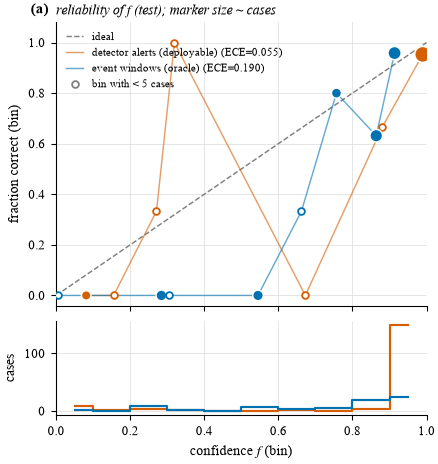

In [3]:
def reliability(df: pd.DataFrame, n_bins: int = 10) -> pd.DataFrame:
    bins = np.clip((df["f"].to_numpy() * n_bins).astype(int), 0, n_bins - 1)
    out = df.assign(bin=bins).groupby("bin").agg(
        f=("f", "mean"), acc=("correct", "mean"), n=("correct", "size"))
    return out.reset_index()


MIN_BIN = 5  # bins with fewer cases are drawn hollow: too thin to read
fig = _fig(3.4, 3.6)
ax, axn = fig.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=0.8, label="ideal")
for name in ("alerts", "events"):
    r = reliability(test[name])
    ax.plot(r["f"], r["acc"], color=COLOR[name], lw=0.8, alpha=0.6,
            label=f"{LABEL[name]} (ECE={reports[name]['ece_test']:.3f})")
    solid = r["n"] >= MIN_BIN
    ax.scatter(r.loc[solid, "f"], r.loc[solid, "acc"], s=12 + 70 * np.sqrt(r.loc[solid, "n"] / len(test[name])),
               color=COLOR[name], edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(r.loc[~solid, "f"], r.loc[~solid, "acc"], s=14, facecolor="white",
               edgecolor=COLOR[name], lw=1.0, zorder=3)
    axn.step(np.arange(10) / 10 + 0.05,
             np.bincount(np.clip((test[name]["f"] * 10).astype(int), 0, 9), minlength=10),
             where="mid", color=COLOR[name], lw=1.2)
ax.set_ylabel("fraction correct (bin)")
ax.set_ylim(-0.04, 1.08)
ax.scatter([], [], s=14, facecolor="white", edgecolor=GREY, label=f"bin with < {MIN_BIN} cases")
ax.legend(loc="upper left", fontsize=6)
_sub(ax, "reliability of $f$ (test); marker size ~ cases")
_label(ax, "(a)")
axn.set_xlim(0, 1)
axn.set_xlabel("confidence $f$ (bin)")
axn.set_ylabel("cases")
_finish(fig, FIGDIR, "decision_calibration")
plt.show()

## (b) Does `f` rank decisions better than the model's own probability?

Risk–coverage on test: sort decisions by a score, accept the top fraction
(coverage), and measure the error among them (risk). Lower is better. The legend
carries the area under each curve (AURC) with its bootstrap 95% CI; the dotted line
is `f` on validation, so a val/test gap shows instead of hiding.

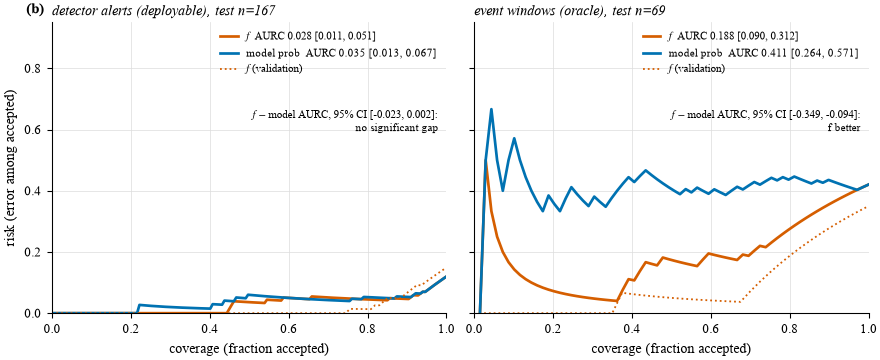

In [4]:
def rc_curve(df: pd.DataFrame, key: str):
    order = df.sort_values(key, ascending=False, kind="stable")
    wrong = 1.0 - order["correct"].to_numpy(dtype=float)
    k = np.arange(1, len(wrong) + 1)
    return k / len(wrong), np.cumsum(wrong) / k


fig = _fig(6.8, 2.8)
axes = fig.subplots(1, 2, sharey=True)
for ax, name in zip(axes, ("alerts", "events"), strict=True):
    rep, df = reports[name], test[name]
    ci = rep["risk_coverage"]["bootstrap_ci"]
    cov, risk = rc_curve(df, "f")
    ax.plot(cov, risk, color=VERM, lw=1.5,
            label="$f$  AURC %.3f [%.3f, %.3f]" % (rep["risk_coverage"]["auc_risk_f"],
                                                 *ci["auc_risk_f"]))
    cov, risk = rc_curve(df, "model_conf")
    ax.plot(cov, risk, color=BLUE, lw=1.5,
            label="model prob  AURC %.3f [%.3f, %.3f]" % (
                rep["risk_coverage"]["auc_risk_model_conf"], *ci["auc_risk_model_conf"]))
    cov, risk = rc_curve(cases[name][cases[name].split == "val"], "f")
    ax.plot(cov, risk, color=VERM, lw=1.0, ls=":", label="$f$ (validation)")
    lo, hi = ci["auc_diff_f_minus_model"]
    verdict = "f better" if hi < 0 else ("model better" if lo > 0 else "no significant gap")
    ax.text(0.98, 0.70, f"$f$ $-$ model AURC, 95% CI [{lo:.3f}, {hi:.3f}]:\n{verdict}",
            transform=ax.transAxes, ha="right", va="top", fontsize=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 0.95)
    ax.set_xlabel("coverage (fraction accepted)")
    ax.legend(loc="upper right", fontsize=6)
    _sub(ax, f"{LABEL[name]}, test n={rep['n_test']}")
axes[0].set_ylabel("risk (error among accepted)")
_label(axes[0], "(b)")
_finish(fig, FIGDIR, "decision_risk_coverage")
plt.show()

## (c) Who decided, and were the proposals right?

Deployable (alerts) run. Left: proposals per tier, split by whether they were
correct. Right: each test case's `f` against the validation-chosen thresholds
(jittered vertically). Tier 3 is also forced by non-convergence, high-risk actions and
adversarial/unknown origins, so it is not only "low `f`".

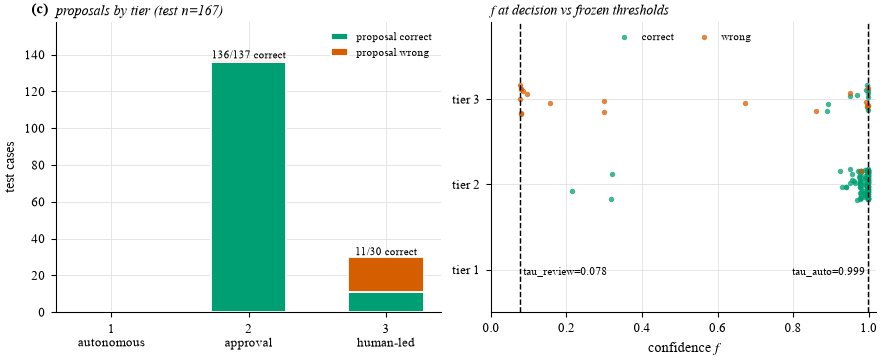

In [5]:
rep, df = reports["alerts"], test["alerts"]
taus = rep["thresholds"]
fig = _fig(6.8, 2.8)
ax1, ax2 = fig.subplots(1, 2)

order = [1, 2, 3]
names = {1: "1\nautonomous", 2: "2\napproval", 3: "3\nhuman-led"}
ok = np.array([int(((df.tier == t) & df.correct).sum()) for t in order])
bad = np.array([int(((df.tier == t) & ~df.correct).sum()) for t in order])
x = np.arange(3)
ax1.bar(x, ok, width=0.55, color=GREEN, label="proposal correct", edgecolor="white", lw=1)
ax1.bar(x, bad, width=0.55, bottom=ok, color=VERM, label="proposal wrong",
        edgecolor="white", lw=1)
ax1.set_xticks(x, [names[t] for t in order])
ax1.set_ylabel("test cases")
ax1.legend(fontsize=6)
for i, (o, b) in enumerate(zip(ok, bad, strict=True)):
    if o + b:
        ax1.text(i, o + b + 1, f"{o}/{o + b} correct", ha="center", fontsize=6)
ax1.set_ylim(0, (ok + bad).max() * 1.15)
_sub(ax1, f"proposals by tier (test n={len(df)})")
_label(ax1, "(c)")

rng = np.random.default_rng(0)
for correct, color, label in ((True, GREEN, "correct"), (False, VERM, "wrong")):
    sub = df[df.correct == correct]
    ax2.scatter(sub["f"], sub["tier"] + rng.uniform(-0.18, 0.18, len(sub)), s=9,
                color=color, alpha=0.75, lw=0, label=label)
for key, xv in (("tau_review", taus["tau_review"]), ("tau_auto", taus["tau_auto"])):
    ax2.axvline(xv, color="black", ls="--", lw=0.8)
    ax2.text(xv, 0.97, " %s=%.3f " % (key, xv), ha="right" if key == "tau_auto" else "left",
             va="center", fontsize=6)
ax2.set_xlabel("confidence $f$")
ax2.set_yticks([1, 2, 3], ["tier 1", "tier 2", "tier 3"])
ax2.set_ylim(0.5, 3.9)
ax2.set_xlim(0, 1.02)
ax2.legend(loc="upper center", ncol=2, fontsize=6)
_sub(ax2, "$f$ at decision vs frozen thresholds")
_finish(fig, FIGDIR, "decision_escalation")
plt.show()

## (d) What happens when a human is in the loop? (simulated operators)

Blueprint §13, Phase 1 simulation on the deployable run. Three operator profiles review
the proposals routed to them: **rubber-stamper** (approves 95%), **skeptic** (rejects
40% at random) and **calibrated** (approves with probability `f`). A rejected or
human-led case is decided by the operator alone, correct with probability
`human_accuracy` (an explicit assumption, swept below). Bars: final error per routing
strategy (mean ± std over Monte-Carlo runs); the operator load (share of cases a human
touches) is under each strategy. These are simulated operators, not a user study.

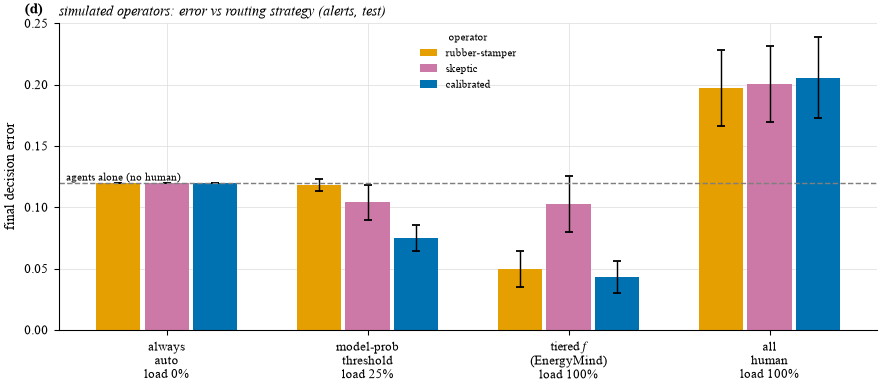

assumptions: {'human_accuracy': 0.8, 'approve_probability': {'rubber_stamper': 0.95, 'skeptic': 0.6, 'calibrated': 'f'}, 'n_sims': 200, 'note': 'simulated operators (blueprint Section 13); not a user study'} | tau_model: 0.7662


final_error  final_error_std  operator_load  \
strategy        operator                                                      
always_auto     rubber_stamper       0.1198           0.0000         0.0000   
                skeptic              0.1198           0.0000         0.0000   
                calibrated           0.1198           0.0000         0.0000   
model_threshold rubber_stamper       0.1182           0.0051         0.2455   
                skeptic              0.1039           0.0144         0.2455   
                calibrated           0.0748           0.0104         0.2455   
tiered_f        rubber_stamper       0.0497           0.0147         1.0000   
                skeptic              0.1028           0.0226         1.0000   
                calibrated           0.0430           0.0132         1.0000   
all_human       rubber_stamper       0.1971           0.0312         1.0000   
                skeptic              0.2004           0.0308         1.0000   
                calibrated           0.2057           0.0328         1.0000   

                                automation_bias_rate  \
strategy        operator                               
always_auto     rubber_stamper                   NaN   
                skeptic                          NaN   
                calibrated                       NaN   
model_threshold rubber_stamper                0.9540   
                skeptic                       0.6027   
                calibrated                    0.3267   
tiered_f        rubber_stamper                0.9500   
                skeptic                       0.6400   
                calibrated                    0.9700   
all_human       rubber_stamper                   NaN   
                skeptic                          NaN   
                calibrated                       NaN   

                                unjustified_rejection_rate  \
strategy        operator                                     
always_auto     rubber_stamper                         NaN   
                skeptic                                NaN   
                calibrated                             NaN   
model_threshold rubber_stamper                      0.0521   
                skeptic                             0.4175   
                calibrated                          0.1154   
tiered_f        rubber_stamper                      0.0518   
                skeptic                             0.3957   
                calibrated                          0.0250   
all_human       rubber_stamper                         NaN   
                skeptic                                NaN   
                calibrated                             NaN   

                                unnecessary_escalation  
strategy        operator                                
always_auto     rubber_stamper                     NaN  
                skeptic                            NaN  
                calibrated                         NaN  
model_threshold rubber_stamper                  0.6341  
                skeptic                         0.6341  
                calibrated                      0.6341  
tiered_f        rubber_stamper                  0.8802  
                skeptic                         0.8802  
                calibrated                      0.8802  
all_human       rubber_stamper                  0.8802  
                skeptic                         0.8802  
                calibrated                      0.8802

In [6]:
sim = reports["alerts"]["operator_simulation"]
table = sim["table"]
strategies = ["always_auto", "model_threshold", "tiered_f", "all_human"]
pretty = {"always_auto": "always\nauto", "model_threshold": "model-prob\nthreshold",
          "tiered_f": "tiered $f$\n(EnergyMind)", "all_human": "all\nhuman"}
operators = ["rubber_stamper", "skeptic", "calibrated"]
op_color = {"rubber_stamper": ORANGE, "skeptic": PURPLE, "calibrated": BLUE}
op_name = {"rubber_stamper": "rubber-stamper", "skeptic": "skeptic", "calibrated": "calibrated"}

fig = _fig(6.8, 3.0)
ax = fig.gca()
width = 0.24
x = np.arange(len(strategies))
for j, op in enumerate(operators):
    err = [table[s][op]["final_error"] for s in strategies]
    sd = [table[s][op]["final_error_std"] for s in strategies]
    ax.bar(x + (j - 1) * width, err, width=width - 0.02, yerr=sd, capsize=2,
           color=op_color[op], label=op_name[op], error_kw={"lw": 0.8})
labels = [f"{pretty[s]}\nload {table[s]['calibrated']['operator_load']:.0%}" for s in strategies]
ax.set_xticks(x, labels)
ax.set_ylabel("final decision error")
ax.axhline(sim["proposal_error_test"], color=GREY, ls="--", lw=0.8)
ax.text(-0.5, sim["proposal_error_test"], "agents alone (no human)", va="bottom",
        ha="left", fontsize=6, color="black")
ax.legend(title="operator", fontsize=6, title_fontsize=6, loc="upper center")
_sub(ax, "simulated operators: error vs routing strategy (alerts, test)")
_label(ax, "(d)")
_finish(fig, FIGDIR, "decision_operator_sim")
plt.show()

rows = []
for s in strategies:
    for op in operators:
        rows.append({"strategy": s, "operator": op, **table[s][op]})
print("assumptions:", sim["assumptions"], "| tau_model:", sim["tau_model"])
pd.DataFrame(rows).set_index(["strategy", "operator"])

In [7]:
sweep = pd.DataFrame(sim["human_accuracy_sweep"]).T
sweep.index.name = "human accuracy"
print("final error (calibrated operator) as the operator's own accuracy varies:")
sweep

final error (calibrated operator) as the operator's own accuracy varies:


,always_auto,model_threshold,tiered_f,all_human
human accuracy,,,,
0.70,0.1198,0.0826,0.0644,0.3039
0.80,0.1198,0.0748,0.0430,0.2057
0.90,0.1198,0.0665,0.0247,0.1029


## (e) What did `f` learn?

The β weights are fitted on the later half of validation (L2 logistic regression);
bars are bootstrap 95% CIs. A CI that crosses 0 means that term carries no reliable
information on this data — the paper reports that rather than dropping the term.
`D` (memory reuse) is 0 when the "seen before" path never fired on the β-fitting split.

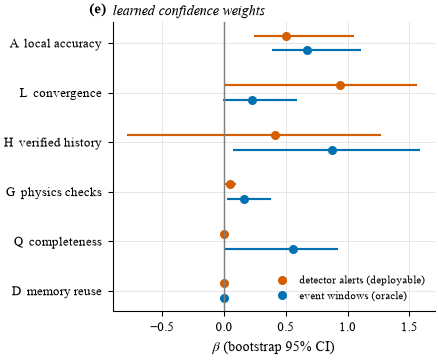

In [8]:
terms = ["logit_A", "L_eff", "logit_H", "G", "Q", "D"]
pretty_terms = {"logit_A": "A  local accuracy", "L_eff": "L  convergence",
                "logit_H": "H  verified history", "G": "G  physics checks",
                "Q": "Q  completeness", "D": "D  memory reuse"}
fig = _fig(3.4, 2.8)
ax = fig.gca()
y = np.arange(len(terms))
for k, name in enumerate(("alerts", "events")):
    coef, ci = reports[name]["coefficients"], reports[name]["coefficients_ci"]
    offset = (k - 0.5) * 0.3
    est = [coef.get(t, 0.0) for t in terms]
    lo = [ci.get(t, [0, 0])[0] for t in terms]
    hi = [ci.get(t, [0, 0])[1] for t in terms]
    ax.hlines(y + offset, lo, hi, color=COLOR[name], lw=1.2)
    ax.plot(est, y + offset, "o", color=COLOR[name], ms=4, label=LABEL[name])
ax.axvline(0, color=GREY, lw=0.8)
ax.set_yticks(y, [pretty_terms[t] for t in terms])
ax.invert_yaxis()
ax.set_xlabel("$\\beta$ (bootstrap 95% CI)")
ax.legend(fontsize=6, loc="lower right")
_sub(ax, "learned confidence weights")
_label(ax, "(e)")
_finish(fig, FIGDIR, "decision_coefficients")
plt.show()

## Reading the figures

The notes below are computed from the two reports, so they stay true when the
reports are regenerated.

In [9]:
al, ev = reports["alerts"], reports["events"]


def verdict(rep):
    lo, hi = rep["risk_coverage"]["bootstrap_ci"]["auc_diff_f_minus_model"]
    return "better than" if hi < 0 else ("worse than" if lo > 0 else "not distinguishable from")


t = al["operator_simulation"]["table"]
best = min(t, key=lambda s: t[s]["calibrated"]["final_error"])
notes = [
    f"(a) ECE of f: {al['ece_test']:.3f} on {al['n_test']} alert cases, "
    f"{ev['ece_test']:.3f} on {ev['n_test']} oracle event windows.",
    f"(b) Ranking: f is {verdict(ev)} the model probability on oracle windows "
    f"(AURC {ev['risk_coverage']['auc_risk_f']:.3f} vs "
    f"{ev['risk_coverage']['auc_risk_model_conf']:.3f}) and {verdict(al)} it on the alert "
    f"stream, where {al['false_alarm_cases']['test']} of {al['n_test']} cases are false "
    "alarms the classifier already dismisses confidently.",
    f"(c) Tiers: tier-2 proposals are {al['tier_accuracy']['2']:.0%} correct, tier-3 "
    f"{al['tier_accuracy']['3']:.0%}; tier 1 holds {al['tier_counts']['1']} cases "
    f"(tau_auto={al['thresholds']['tau_auto']:.3f} meets the "
    "2% error target on validation only that high).",
    "(d) Calibrated operator, final error / load: "
    + "; ".join(
        f"{s} {t[s]['calibrated']['final_error']:.3f} / {t[s]['calibrated']['operator_load']:.0%}"
        for s in t
    )
    + f". Lowest error: {best}.",
    "(e) Terms whose 95% CI excludes 0 (alerts): "
    + ", ".join(k for k, (lo, hi) in al["coefficients_ci"].items() if k != "b0" and lo > 0)
    + ".",
]
print("\n".join(notes))

(a) ECE of f: 0.055 on 167 alert cases, 0.190 on 69 oracle event windows.
(b) Ranking: f is better than the model probability on oracle windows (AURC 0.188 vs 0.411) and not distinguishable from it on the alert stream, where 133 of 167 cases are false alarms the classifier already dismisses confidently.
(c) Tiers: tier-2 proposals are 99% correct, tier-3 37%; tier 1 holds 0 cases (tau_auto=0.999 meets the 2% error target on validation only that high).
(d) Calibrated operator, final error / load: always_auto 0.120 / 0%; model_threshold 0.075 / 25%; tiered_f 0.043 / 100%; all_human 0.206 / 100%. Lowest error: tiered_f.
(e) Terms whose 95% CI excludes 0 (alerts): logit_A, G.
